<a href="https://colab.research.google.com/github/josemartinlabarca/mineria-datos-churn-telco/blob/main/IEI097_Lab2_12_JOSELABARCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧠 Actividad 2.12 — Laboratorio: MLP + MLflow
**IEI097 Minería de Datos · Unidad II · Semanas 11–12**

| | |
|---|---|
| **Nombre** | José Labarca |
| **Número de lista (SEED)** | 7 nose cual ese mi numer|
| **Fecha** | 10/11/2026|

Objetivo: entrenar un perceptrón multicapa (MLPClassifier) para clasificar tumores de mama (B/M) del dataset
*Breast Cancer Wisconsin (Diagnostic)* y registrar cada experimento con **MLflow** desplegado en esta sesión de Colab
(servidor + SQLite + túnel ngrok).

**Requisitos en Colab Secrets (🔑):** `KAGGLE_API_TOKEN` (o `KAGGLE_USERNAME` + `KAGGLE_KEY`) y `NGROK_AUTHTOKEN`, con “Acceso desde el notebook” activado.

## Paso 1 — Entorno y semilla personal
Instalo las dos librerías nuevas. Si Colab pide reiniciar la sesión, reinicio y vuelvo a ejecutar desde el inicio.

In [10]:
!pip install -q mlflow pyngrok kagglehub

In [11]:
import os, random, time, subprocess, warnings, platform
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, recall_score, f1_score,
                             precision_score, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.exceptions import ConvergenceWarning

import mlflow
from mlflow.tracking import MlflowClient
from mlflow.entities import Metric

# >>> CAMBIA ESTE VALOR POR TU NÚMERO DE LISTA <<<
SEED = 7

random.seed(SEED)
np.random.seed(SEED)

APELLIDO = "Labarca"
EXPERIMENTO = f"IEI097-L2.12-{APELLIDO}"

# Observabilidad: el entorno también forma parte del experimento
VERSIONES = {
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "scikit-learn": sklearn.__version__,
    "mlflow": mlflow.__version__,
}
for k, v in VERSIONES.items():
    print(f"{k:>13}: {v}")
print("SEED =", SEED)

       python: 3.13.18
       pandas: 2.2.3
        numpy: 2.4.6
 scikit-learn: 1.6.1
       mlflow: 3.18.0
SEED = 7


## Paso 2 — Carga y preparación de los datos
Descargo el dataset con `kagglehub` usando las credenciales guardadas en Colab Secrets (igual que en el Laboratorio 02).

In [12]:
from google.colab import userdata
import kagglehub

def secreto(nombre):
    # Lee un secreto de Colab; devuelve None si no existe o no tiene acceso
    try:
        return userdata.get(nombre)
    except Exception as e:
        print(f"  (secreto {nombre}: {type(e).__name__})")
        return None

# Acepta cualquiera de los dos formatos de credenciales de Kaggle:
#  a) token nuevo (empieza con KGAT_...) guardado como KAGGLE_API_TOKEN
#  b) usuario + key (kaggle.json) guardados como KAGGLE_USERNAME y KAGGLE_KEY
token = secreto("KAGGLE_API_TOKEN")
usuario, key = secreto("KAGGLE_USERNAME"), secreto("KAGGLE_KEY")
if token:
    os.environ["KAGGLE_API_TOKEN"] = token
    print("Credenciales: KAGGLE_API_TOKEN")
elif usuario and key:
    os.environ["KAGGLE_USERNAME"], os.environ["KAGGLE_KEY"] = usuario, key
    print("Credenciales: KAGGLE_USERNAME + KAGGLE_KEY")
else:
    print("Sin credenciales: se intenta la descarga anónima (el dataset es público)")

ruta = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")
print("Carpeta descargada:", ruta)
print("Archivos:", os.listdir(ruta))

  (secreto KAGGLE_USERNAME: SecretNotFoundError)
  (secreto KAGGLE_KEY: SecretNotFoundError)
Credenciales: KAGGLE_API_TOKEN
Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.
Carpeta descargada: /kaggle/input/breast-cancer-wisconsin-data
Archivos: ['data.csv']


In [13]:
# Confirmo cuál es el CSV principal antes de cargarlo
csvs = [f for f in os.listdir(ruta) if f.endswith(".csv")]
print("CSV encontrados:", csvs)
CSV = os.path.join(ruta, csvs[0])

df = pd.read_csv(CSV)
print("shape:", df.shape)
df.info()
df.head()

CSV encontrados: ['data.csv']
shape: (569, 33)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [14]:
# ¿Qué columna está completamente vacía?
nulos = df.isna().sum()
print(nulos[nulos > 0])
print("Columnas 100% vacías:", list(df.columns[df.isna().all()]))

Unnamed: 32    569
dtype: int64
Columnas 100% vacías: ['Unnamed: 32']


In [15]:
# Elimino la columna residuo (Unnamed: 32) y el identificador id
df = df.drop(columns=["id"] + list(df.columns[df.isna().all()]))

# Codifico la etiqueta: M -> 1 (maligno, clase de interés), B -> 0 (benigno)
df["diagnosis"] = df["diagnosis"].map({"M": 1, "B": 0})

print("shape final:", df.shape)
print("Nulos restantes:", int(df.isna().sum().sum()))

balance = df["diagnosis"].value_counts()
print("\nBalance de clases (0 = B, 1 = M):")
print(pd.DataFrame({"n": balance, "%": (df["diagnosis"].value_counts(normalize=True) * 100).round(2)}))

shape final: (569, 31)
Nulos restantes: 0

Balance de clases (0 = B, 1 = M):
             n      %
diagnosis            
0          357  62.74
1          212  37.26


**Balance de clases:** _(anotar con tus palabras: cuántos benignos y cuántos malignos hay, y si el dataset está balanceado o no)._

In [16]:
# Evidencia de escala
vars_escala = ["radius_mean", "area_mean", "smoothness_mean"]
escala = df[vars_escala].agg(["min", "max"]).T
escala["rango"] = escala["max"] - escala["min"]
display(escala)

r = escala["rango"]
print(f"El rango de area_mean es {r['area_mean']/r['radius_mean']:,.1f} veces el de radius_mean")
print(f"El rango de area_mean es {r['area_mean']/r['smoothness_mean']:,.1f} veces el de smoothness_mean")
print(f"El rango de radius_mean es {r['radius_mean']/r['smoothness_mean']:,.1f} veces el de smoothness_mean")

,min,max,rango
radius_mean,6.98100,28.1100,21.12900
area_mean,143.50000,2501.0000,2357.50000
smoothness_mean,0.05263,0.1634,0.11077


El rango de area_mean es 111.6 veces el de radius_mean
El rango de area_mean es 21,282.8 veces el de smoothness_mean
El rango de radius_mean es 190.7 veces el de smoothness_mean


**Interpretación de la escala:** _(escribe cuántas veces mayor es el rango de una variable respecto de otra y por qué eso puede afectar a una red neuronal)._

## Paso 3 — Partición estratificada (fija para todo el laboratorio)

In [17]:
X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

SPLIT_SEED = SEED
print("Train:", X_train.shape, " Test:", X_test.shape)
print(pd.DataFrame({
    "total": y.value_counts(normalize=True),
    "train": y_train.value_counts(normalize=True),
    "test":  y_test.value_counts(normalize=True),
}).round(4).rename(index={0: "B (0)", 1: "M (1)"}))

Train: (455, 30)  Test: (114, 30)
            total   train    test
diagnosis                        
B (0)      0.6274  0.6264  0.6316
M (1)      0.3726  0.3736  0.3684


La estratificación mantiene la misma proporción de malignos en train y test. Esta partición **no cambia** en el resto del
laboratorio: cualquier diferencia entre runs se debe solo al cambio que introduzco (un cambio a la vez).

## Paso 4 — Desplegar MLflow en Colab y abrirlo en el navegador
⚠️ No ejecutar esta celda dos veces seguidas. Si aparece `ERR_NGROK_108`, cerrar la otra sesión de ngrok.

In [18]:
import requests
from google.colab import userdata
from pyngrok import ngrok

# 1) Servidor de seguimiento (tracking server) con SQLite como backend store.
#    MLflow >= 3.5 rechaza por defecto cualquier Host distinto de localhost.
def servidor_responde():
    try:
        return requests.get("http://127.0.0.1:5000/health", timeout=5).ok
    except requests.exceptions.RequestException:   # ConnectionError, ReadTimeout, etc.
        return False

if servidor_responde():
    print("El servidor MLflow ya estaba corriendo: se reutiliza.")
else:
    env = dict(os.environ,
               MLFLOW_SERVER_ALLOWED_HOSTS="*",
               MLFLOW_SERVER_CORS_ALLOWED_ORIGINS="*")
    proceso_mlflow = subprocess.Popen(
        ["mlflow", "server",
         "--backend-store-uri", "sqlite:///mlflow.db",
         "--host", "127.0.0.1", "--port", "5000"], env=env,
        stdout=open("mlflow_server.log", "w"), stderr=subprocess.STDOUT)  # logs del servidor a archivo

    # 2) Esperar a que el servidor responda (la primera vez crea la base SQLite y puede tardar 1-2 min)
    print("Iniciando servidor MLflow", end="")
    for _ in range(180):
        if servidor_responde():
            break
        if proceso_mlflow.poll() is not None:          # el proceso murió
            break
        print(".", end="", flush=True)
        time.sleep(1)
    print()

    if not servidor_responde():
        print("❌ El servidor no respondió. Últimas líneas del log:")
        print("".join(open("mlflow_server.log").readlines()[-25:]))
        raise RuntimeError("MLflow no arrancó: revisa el log de arriba")
print("✅ Servidor MLflow respondiendo en http://127.0.0.1:5000")

# 3) Túnel público con ngrok
ngrok.set_auth_token(userdata.get("NGROK_AUTHTOKEN"))
ngrok.kill()                    # cierra túneles anteriores
tunel = ngrok.connect(5000)
print("MLflow UI:", tunel.public_url)

El servidor MLflow ya estaba corriendo: se reutiliza.
✅ Servidor MLflow respondiendo en http://127.0.0.1:5000
MLflow UI: https://pacifier-appetizer-delicate.ngrok-free.dev


In [19]:
mlflow.set_tracking_uri("http://127.0.0.1:5000")
exp = mlflow.set_experiment(EXPERIMENTO)
print("Experimento:", exp.name, "| id:", exp.experiment_id)

2026/11/11 22:54:04 INFO mlflow.tracking.fluent: Experiment with name 'IEI097-L2.12-Labarca' does not exist. Creating a new experiment.


Experimento: IEI097-L2.12-Labarca | id: 1


Abrí la URL impresa (si ngrok muestra un aviso, presionar **Visit Site**) y verifiqué la interfaz de MLflow vacía.
📸 *Toma la primera captura aquí.*

## Paso 5 — Experimentos controlados: un cambio a la vez

### Hipótesis (escrita ANTES de ejecutar los runs A y B)
_Escribe aquí, con tus palabras: ¿el escalado mejorará, empeorará o no cambiará el resultado? Justifica con lo que sabes de feature scaling
(magnitudes distintas, suma ponderada, saturación de activaciones, descenso del gradiente)._

In [20]:
warnings.filterwarnings("ignore", category=ConvergenceWarning)

def correr_experimento(nombre, escalado=True, capas=(30,), activacion="relu",
                       alpha=1e-4, max_iter=500, learning_rate_init=1e-3,
                       seed_modelo=SEED, fase="experimentos", descripcion=""):
    """Entrena un MLP con la configuración dada y registra todo en MLflow."""
    mlp = MLPClassifier(hidden_layer_sizes=capas, activation=activacion, alpha=alpha,
                        max_iter=max_iter, learning_rate_init=learning_rate_init,
                        random_state=seed_modelo)
    pasos = [("scaler", StandardScaler())] if escalado else []
    modelo = Pipeline(pasos + [("mlp", mlp)])   # el scaler se ajusta SOLO con train

    with mlflow.start_run(run_name=nombre) as run:
        # ---- Parámetros (entradas)
        mlflow.log_params({
            "escalado": escalado,
            "hidden_layer_sizes": str(capas),
            "activation": activacion,
            "alpha": alpha,
            "max_iter": max_iter,
            "learning_rate_init": learning_rate_init,
            "random_state": seed_modelo,
            "split_seed": SPLIT_SEED,
            "test_size": 0.2,
            "solver": mlp.solver,
        })
        # ---- Etiquetas (metadatos) + entorno
        mlflow.set_tag("fase", fase)
        if descripcion:
            mlflow.set_tag("cambio", descripcion)
        for k, v in VERSIONES.items():
            mlflow.set_tag(f"version_{k}", v)

        # ---- Entrenamiento
        t0 = time.time()
        modelo.fit(X_train, y_train)
        duracion = time.time() - t0
        red = modelo.named_steps["mlp"]

        # ---- Métricas (salidas)
        pred_tr = modelo.predict(X_train)
        pred_te = modelo.predict(X_test)
        metricas = {
            "accuracy_train": accuracy_score(y_train, pred_tr),
            "accuracy_test":  accuracy_score(y_test, pred_te),
            "recall_maligno": recall_score(y_test, pred_te, pos_label=1),
            "precision_maligno": precision_score(y_test, pred_te, pos_label=1, zero_division=0),
            "f1": f1_score(y_test, pred_te, pos_label=1),
            "n_iter": red.n_iter_,
            "convergio": int(red.n_iter_ < max_iter),
            "duracion_seg": duracion,
        }
        cm = confusion_matrix(y_test, pred_te)
        metricas["falsos_negativos"] = int(cm[1, 0])
        metricas["falsos_positivos"] = int(cm[0, 1])
        mlflow.log_metrics(metricas)

        # ---- Curva de pérdida por época
        #      (equivale a mlflow.log_metric("train_loss", valor, step=epoca) en un solo envío)
        ts = int(time.time() * 1000)
        MlflowClient().log_batch(run.info.run_id, metrics=[
            Metric("train_loss", float(p), ts, epoca) for epoca, p in enumerate(red.loss_curve_, start=1)])

        # ---- Artefacto: matriz de confusión del conjunto de prueba
        fig, ax = plt.subplots(figsize=(4.5, 4))
        ConfusionMatrixDisplay(cm, display_labels=["Benigno (0)", "Maligno (1)"]).plot(
            ax=ax, cmap="Blues", colorbar=False)
        ax.set_title(f"{nombre}\nacc={metricas['accuracy_test']:.4f} | recall M={metricas['recall_maligno']:.4f}")
        fig.tight_layout()
        mlflow.log_figure(fig, "matriz_confusion_test.png")
        plt.show()
        plt.close(fig)

    print(f"[{nombre}] acc_train={metricas['accuracy_train']:.4f}  acc_test={metricas['accuracy_test']:.4f}  "
          f"recall_M={metricas['recall_maligno']:.4f}  f1={metricas['f1']:.4f}  "
          f"FN={metricas['falsos_negativos']}  iter={metricas['n_iter']}")
    return {"run": nombre, "run_id": run.info.run_id, **metricas, "loss_curve": red.loss_curve_}

resultados = {}

### Run A

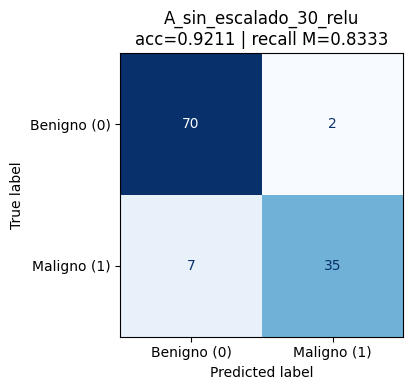

🏃 View run A_sin_escalado_30_relu at: http://127.0.0.1:5000/#/experiments/1/runs/8d4e8947d2024fd4a722100e042113fa
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
[A_sin_escalado_30_relu] acc_train=0.9407  acc_test=0.9211  recall_M=0.8333  f1=0.8861  FN=7  iter=225


In [21]:
resultados["A"] = correr_experimento("A_sin_escalado_30_relu", escalado=False, capas=(30,), activacion="relu",
                                         descripcion="Punto de partida")

**Interpretación run A:** _(1–2 líneas: ¿cómo le fue sin escalar? mira la exactitud, el recall, los FN y si convergió)._

### Run B

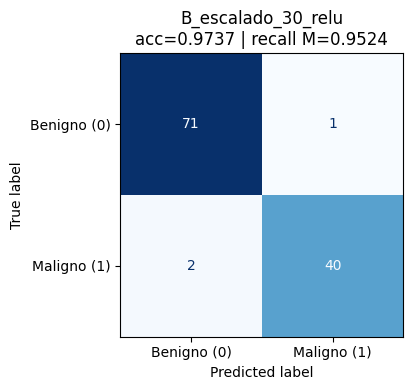

🏃 View run B_escalado_30_relu at: http://127.0.0.1:5000/#/experiments/1/runs/1515096472294189ac784c8b302a469e
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
[B_escalado_30_relu] acc_train=0.9956  acc_test=0.9737  recall_M=0.9524  f1=0.9639  FN=2  iter=387


In [22]:
resultados["B"] = correr_experimento("B_escalado_30_relu", escalado=True, capas=(30,), activacion="relu",
                                         descripcion="Se agrega escalado")

**Interpretación run B y contraste con la hipótesis:** _(compara con A: ¿se cumplió tu hipótesis? ¿cambió el número de iteraciones o la curva de pérdida?)._

### Run C

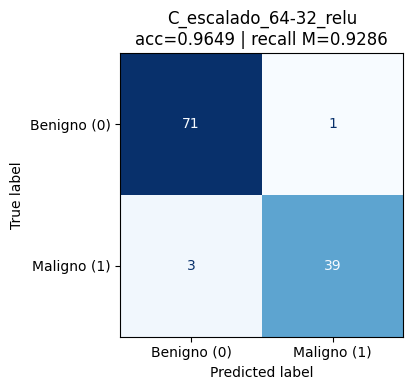

🏃 View run C_escalado_64-32_relu at: http://127.0.0.1:5000/#/experiments/1/runs/9868e45074ce4ccaae7dc9f67d9c9801
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
[C_escalado_64-32_relu] acc_train=1.0000  acc_test=0.9649  recall_M=0.9286  f1=0.9512  FN=3  iter=155


In [23]:
resultados["C"] = correr_experimento("C_escalado_64-32_relu", escalado=True, capas=(64, 32), activacion="relu",
                                         descripcion="Cambia la arquitectura")

**Interpretación run C:** _(compara con B: ¿más capas/neuronas mejoraron algo? ¿hay señales de sobreajuste: acc_train vs acc_test?)._

### Run D

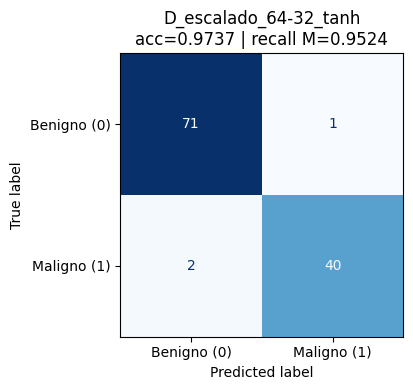

🏃 View run D_escalado_64-32_tanh at: http://127.0.0.1:5000/#/experiments/1/runs/17b56c304fc9481197a589a2d9c13cd1
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
[D_escalado_64-32_tanh] acc_train=0.9978  acc_test=0.9737  recall_M=0.9524  f1=0.9639  FN=2  iter=282


In [24]:
resultados["D"] = correr_experimento("D_escalado_64-32_tanh", escalado=True, capas=(64, 32), activacion="tanh",
                                         descripcion="Cambia la función de activación")

**Interpretación run D:** _(compara con C: ¿qué efecto tuvo cambiar relu por tanh?)._

### Runs opcionales (variando regularización y tasa de aprendizaje sobre la configuración C)

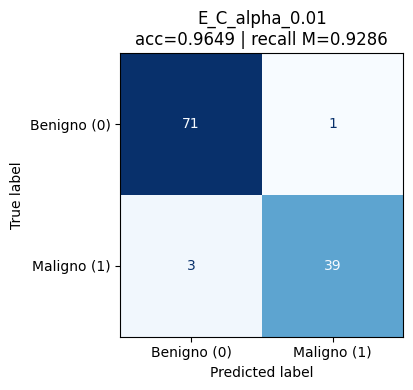

🏃 View run E_C_alpha_0.01 at: http://127.0.0.1:5000/#/experiments/1/runs/25c2cf840ac3445b9c5d38f289254510
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
[E_C_alpha_0.01] acc_train=1.0000  acc_test=0.9649  recall_M=0.9286  f1=0.9512  FN=3  iter=168


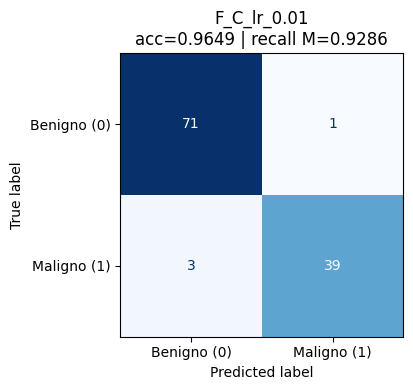

🏃 View run F_C_lr_0.01 at: http://127.0.0.1:5000/#/experiments/1/runs/ceaa5aacc90d458da4f8bf975c1392de
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
[F_C_lr_0.01] acc_train=1.0000  acc_test=0.9649  recall_M=0.9286  f1=0.9512  FN=3  iter=52


In [25]:
resultados["E"] = correr_experimento("E_C_alpha_0.01", escalado=True, capas=(64, 32), activacion="relu",
                                     alpha=0.01, descripcion="C con mayor regularización L2 (alpha=0.01)")
resultados["F"] = correr_experimento("F_C_lr_0.01", escalado=True, capas=(64, 32), activacion="relu",
                                     learning_rate_init=0.01, descripcion="C con learning_rate_init=0.01")

**Interpretación runs E y F:** _(¿la regularización o una tasa de aprendizaje mayor cambiaron la convergencia o las métricas?)._

,accuracy_train,accuracy_test,recall_maligno,f1,falsos_negativos,falsos_positivos,n_iter,convergio
run,,,,,,,,
A_sin_escalado_30_relu,0.9407,0.9211,0.8333,0.8861,7,2,225,1
B_escalado_30_relu,0.9956,0.9737,0.9524,0.9639,2,1,387,1
C_escalado_64-32_relu,1.0000,0.9649,0.9286,0.9512,3,1,155,1
D_escalado_64-32_tanh,0.9978,0.9737,0.9524,0.9639,2,1,282,1
E_C_alpha_0.01,1.0000,0.9649,0.9286,0.9512,3,1,168,1
F_C_lr_0.01,1.0000,0.9649,0.9286,0.9512,3,1,52,1


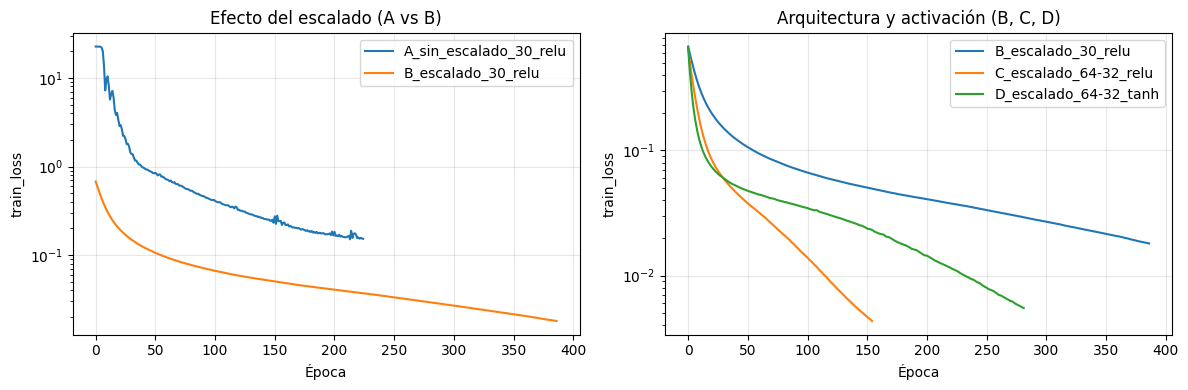

In [26]:
# Resumen de la fase de experimentos
cols = ["run", "accuracy_train", "accuracy_test", "recall_maligno", "f1",
        "falsos_negativos", "falsos_positivos", "n_iter", "convergio"]
tabla_exp = pd.DataFrame([{k: r[k] for k in cols} for r in resultados.values()]).set_index("run")
display(tabla_exp.round(4))

# Curvas de pérdida A vs B (efecto del escalado) y C vs D
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for clave in ["A", "B"]:
    axes[0].plot(resultados[clave]["loss_curve"], label=resultados[clave]["run"])
axes[0].set(title="Efecto del escalado (A vs B)", xlabel="Época", ylabel="train_loss", yscale="log")
for clave in ["B", "C", "D"]:
    axes[1].plot(resultados[clave]["loss_curve"], label=resultados[clave]["run"])
axes[1].set(title="Arquitectura y activación (B, C, D)", xlabel="Época", ylabel="train_loss", yscale="log")
for ax in axes:
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Actualicé la interfaz de MLflow y comprobé que cada run aparece con sus parámetros y métricas.
📸 *Captura de la tabla de ejecuciones.*

## Paso 6 — Semilla y replicación
### 6.1 Variabilidad: configuración C con 5 semillas del modelo (partición fija)

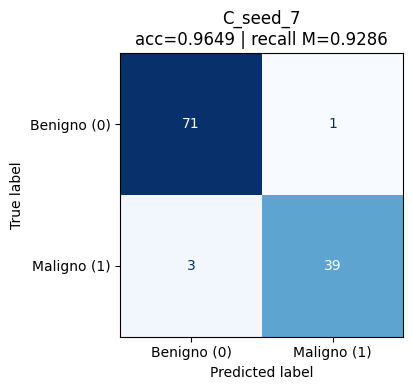

🏃 View run C_seed_7 at: http://127.0.0.1:5000/#/experiments/1/runs/7e0f30a3599c4e8db948d6fe991410cd
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
[C_seed_7] acc_train=1.0000  acc_test=0.9649  recall_M=0.9286  f1=0.9512  FN=3  iter=155


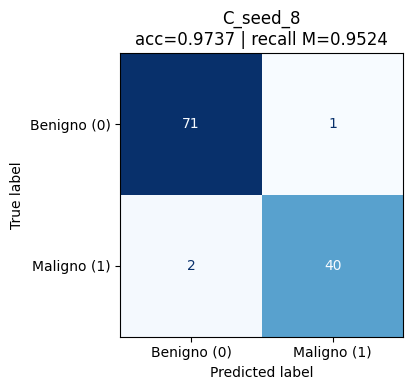

🏃 View run C_seed_8 at: http://127.0.0.1:5000/#/experiments/1/runs/46f7d49c78ff4156a71d5adcb90233e8
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
[C_seed_8] acc_train=1.0000  acc_test=0.9737  recall_M=0.9524  f1=0.9639  FN=2  iter=155


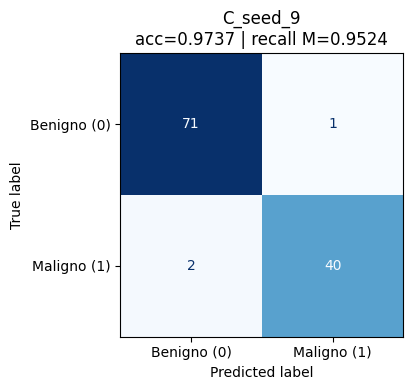

🏃 View run C_seed_9 at: http://127.0.0.1:5000/#/experiments/1/runs/0a702112b78d4ca981e2d2d7bd7fa517
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
[C_seed_9] acc_train=1.0000  acc_test=0.9737  recall_M=0.9524  f1=0.9639  FN=2  iter=169


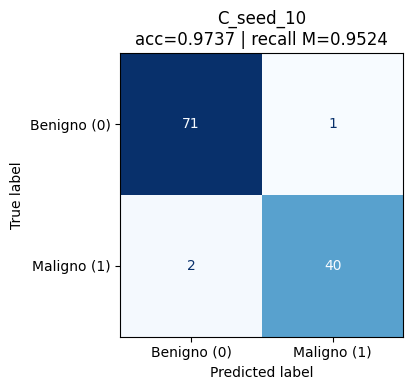

🏃 View run C_seed_10 at: http://127.0.0.1:5000/#/experiments/1/runs/6a1d3ac45c0942f28d42704d6e4472f4
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
[C_seed_10] acc_train=1.0000  acc_test=0.9737  recall_M=0.9524  f1=0.9639  FN=2  iter=158


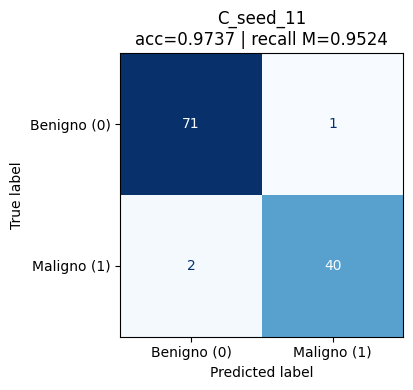

🏃 View run C_seed_11 at: http://127.0.0.1:5000/#/experiments/1/runs/c87a27418ada4def9df60da5152dd4fa
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
[C_seed_11] acc_train=1.0000  acc_test=0.9737  recall_M=0.9524  f1=0.9639  FN=2  iter=177


In [27]:
resultados_semillas = []
for s in range(SEED, SEED + 5):
    r = correr_experimento(f"C_seed_{s}", escalado=True, capas=(64, 32), activacion="relu",
                           seed_modelo=s, fase="semillas",
                           descripcion=f"Config. C con semilla del modelo = {s}")
    r["seed"] = s
    resultados_semillas.append(r)

### 6.2 Replicación: configuración C otra vez con la SEED original

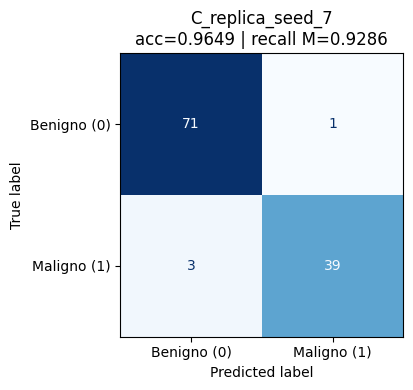

🏃 View run C_replica_seed_7 at: http://127.0.0.1:5000/#/experiments/1/runs/8dbb896183684ca9a6f1d8c121c5545f
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
[C_replica_seed_7] acc_train=1.0000  acc_test=0.9649  recall_M=0.9286  f1=0.9512  FN=3  iter=155


,run C,réplica,diferencia_abs
accuracy_train,1.000000,1.000000,0.0
accuracy_test,0.964912,0.964912,0.0
recall_maligno,0.928571,0.928571,0.0
f1,0.951220,0.951220,0.0
n_iter,155.000000,155.000000,0.0
falsos_negativos,3.000000,3.000000,0.0


Diferencia máxima en la curva de pérdida: 0.0
✅ Replicación EXACTA: mismas métricas y misma curva de pérdida.


In [28]:
resultados["replica"] = correr_experimento(f"C_replica_seed_{SEED}", escalado=True, capas=(64, 32),
                                           activacion="relu", seed_modelo=SEED, fase="replica",
                                           descripcion="Réplica exacta del run C")

metricas_cmp = ["accuracy_train", "accuracy_test", "recall_maligno", "f1", "n_iter", "falsos_negativos"]
cmp = pd.DataFrame({
    "run C": [resultados["C"][m] for m in metricas_cmp],
    "réplica": [resultados["replica"][m] for m in metricas_cmp],
}, index=metricas_cmp)
cmp["diferencia_abs"] = (cmp["run C"] - cmp["réplica"]).abs()
display(cmp)

dif_loss = np.max(np.abs(np.array(resultados["C"]["loss_curve"]) - np.array(resultados["replica"]["loss_curve"]))) \
    if len(resultados["C"]["loss_curve"]) == len(resultados["replica"]["loss_curve"]) else np.inf
print("Diferencia máxima en la curva de pérdida:", dif_loss)

if cmp["diferencia_abs"].max() == 0 and dif_loss == 0:
    print("✅ Replicación EXACTA: mismas métricas y misma curva de pérdida.")
elif cmp["diferencia_abs"].max() < 1e-10 and dif_loss < 1e-10:
    print("✅ Replicación con diferencias solo de redondeo numérico (≈1e-12).")
else:
    print("❌ No coinciden: revisar qué fuente de aleatoriedad quedó sin fijar (partición, pesos iniciales, shuffle).")

**Comentario de replicación:** _(¿coincidieron exactamente? explica por qué: random_state fija la partición, los pesos iniciales y el orden de los mini-lotes)._

### 6.3 Variación entre semillas

In [29]:
tabla_sem = pd.DataFrame([{k: r[k] for k in ["seed", "accuracy_test", "recall_maligno", "f1", "falsos_negativos", "n_iter"]}
                          for r in resultados_semillas]).set_index("seed")
display(tabla_sem.round(4))

resumen_sem = tabla_sem[["accuracy_test", "recall_maligno"]].agg(["min", "max"]).T
resumen_sem["rango"] = resumen_sem["max"] - resumen_sem["min"]
resumen_sem["media"] = tabla_sem[["accuracy_test", "recall_maligno"]].mean()
resumen_sem["desv_est"] = tabla_sem[["accuracy_test", "recall_maligno"]].std()
display(resumen_sem.round(4))

# ¿La variación entre semillas es mayor o menor que las diferencias entre configuraciones?
dif_conf = pd.DataFrame({
    "B - A (escalado)":     tabla_exp.loc[resultados["B"]["run"], ["accuracy_test", "recall_maligno"]] - tabla_exp.loc[resultados["A"]["run"], ["accuracy_test", "recall_maligno"]],
    "C - B (arquitectura)": tabla_exp.loc[resultados["C"]["run"], ["accuracy_test", "recall_maligno"]] - tabla_exp.loc[resultados["B"]["run"], ["accuracy_test", "recall_maligno"]],
    "D - C (activación)":   tabla_exp.loc[resultados["D"]["run"], ["accuracy_test", "recall_maligno"]] - tabla_exp.loc[resultados["C"]["run"], ["accuracy_test", "recall_maligno"]],
}).T
dif_conf["supera_rango_semillas_acc"] = dif_conf["accuracy_test"].abs() > resumen_sem.loc["accuracy_test", "rango"]
dif_conf["supera_rango_semillas_recall"] = dif_conf["recall_maligno"].abs() > resumen_sem.loc["recall_maligno", "rango"]
print("Diferencias entre configuraciones vs. rango observado entre semillas:")
display(dif_conf.round(4))

# Una muestra del test vale 1/len(y_test) de exactitud: sirve para dimensionar las diferencias
print(f"1 tumor mal clasificado en test = {1/len(y_test):.4f} de exactitud | "
      f"1 maligno no detectado = {1/y_test.sum():.4f} de recall")

,accuracy_test,recall_maligno,f1,falsos_negativos,n_iter
seed,,,,,
7,0.9649,0.9286,0.9512,3,155
8,0.9737,0.9524,0.9639,2,155
9,0.9737,0.9524,0.9639,2,169
10,0.9737,0.9524,0.9639,2,158
11,0.9737,0.9524,0.9639,2,177


,min,max,rango,media,desv_est
accuracy_test,0.9649,0.9737,0.0088,0.9719,0.0039
recall_maligno,0.9286,0.9524,0.0238,0.9476,0.0106


Diferencias entre configuraciones vs. rango observado entre semillas:


,accuracy_test,recall_maligno,supera_rango_semillas_acc,supera_rango_semillas_recall
B - A (escalado),0.0526,0.1190,True,True
C - B (arquitectura),-0.0088,-0.0238,False,False
D - C (activación),0.0088,0.0238,False,False


1 tumor mal clasificado en test = 0.0088 de exactitud | 1 maligno no detectado = 0.0238 de recall


## Paso 7 — Análisis en MLflow y exportación de evidencia
**En la interfaz de MLflow** (📸 tomar capturas con la URL de ngrok visible):
1. Ordenar la tabla por `recall_maligno` y verificar ≥ 10 runs.
2. Seleccionar ≥ 4 runs → **Compare**.
3. Ver `train_loss` de al menos dos runs superpuestos.
4. Abrir un run y ubicar el artefacto `matriz_confusion_test.png`.

In [30]:
runs_df = mlflow.search_runs(experiment_names=[EXPERIMENTO], order_by=["attributes.start_time ASC"])
print("Total de runs registrados:", len(runs_df))

columnas = (["run_id", "tags.mlflow.runName", "tags.fase", "tags.cambio", "start_time"]
            + [c for c in runs_df.columns if c.startswith("params.")]
            + [c for c in runs_df.columns if c.startswith("metrics.")])
runs_export = runs_df[[c for c in columnas if c in runs_df.columns]]
runs_export.to_csv("runs.csv", index=False)
print("runs.csv exportado con", runs_export.shape[1], "columnas")

display(runs_export[["tags.mlflow.runName", "tags.fase", "params.escalado", "params.hidden_layer_sizes",
                     "params.activation", "params.random_state", "metrics.accuracy_test",
                     "metrics.recall_maligno", "metrics.f1", "metrics.n_iter"]]
        .sort_values("metrics.recall_maligno", ascending=False).round(4))

Total de runs registrados: 12
runs.csv exportado con 26 columnas


,tags.mlflow.runName,tags.fase,params.escalado,params.hidden_layer_sizes,params.activation,params.random_state,metrics.accuracy_test,metrics.recall_maligno,metrics.f1,metrics.n_iter
1,B_escalado_30_relu,experimentos,True,"(30,)",relu,7,0.9737,0.9524,0.9639,387.0
3,D_escalado_64-32_tanh,experimentos,True,"(64, 32)",tanh,7,0.9737,0.9524,0.9639,282.0
10,C_seed_11,semillas,True,"(64, 32)",relu,11,0.9737,0.9524,0.9639,177.0
7,C_seed_8,semillas,True,"(64, 32)",relu,8,0.9737,0.9524,0.9639,155.0
9,C_seed_10,semillas,True,"(64, 32)",relu,10,0.9737,0.9524,0.9639,158.0
8,C_seed_9,semillas,True,"(64, 32)",relu,9,0.9737,0.9524,0.9639,169.0
6,C_seed_7,semillas,True,"(64, 32)",relu,7,0.9649,0.9286,0.9512,155.0
2,C_escalado_64-32_relu,experimentos,True,"(64, 32)",relu,7,0.9649,0.9286,0.9512,155.0
4,E_C_alpha_0.01,experimentos,True,"(64, 32)",relu,7,0.9649,0.9286,0.9512,168.0
5,F_C_lr_0.01,experimentos,True,"(64, 32)",relu,7,0.9649,0.9286,0.9512,52.0


In [31]:
from google.colab import files
files.download("runs.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Paso 8 — Preguntas de cierre

---

### 1️⃣ ¿Qué cambió al escalar las variables?

Al escalar, el cambio se refleja en que **sube la exactitud y el recall, y bajan los falsos negativos**:

| Run | Exactitud (test) | Recall maligno | Falsos negativos |
|---|---|---|---|
| `A_sin_escalado_30_relu` | 0,9211 | 0,8333 | 7 |
| `B_escalado_30_relu` | **0,9737** | **0,9524** | **2** |

Esto significa que el modelo **deja escapar menos tumores malignos: de 7 a 2**.

Sin escalar, las variables grandes dominan la suma de cada neurona; por ejemplo, `area_mean` (~2500) frente a `smoothness_mean` (~0,16). El **escalado (StandardScaler)** las iguala, para que todas aporten.

---

### 2️⃣ ¿Más capas y neuronas mejoraron el resultado?

**No mejoró.** Al pasar de `B_escalado_30_relu` a `C_escalado_64-32_relu`:

- La exactitud bajó de **0,9737 a 0,9649**.
- Los falsos negativos subieron de **2 a 3**.

La diferencia es de **1 tumor**, y con las **semillas 8 a 11** la configuración C saca lo mismo que B, así que **no hay una diferencia real**.

Además, el accuracy de entrenamiento llegó a **1,0** en C, pero el test no mejoró. Eso es **sobreajuste (overfitting)**.

---

### 3️⃣ ¿Qué tan grande fue la variación entre semillas?

| Métrica | Mínimo | Máximo | Rango |
|---|---|---|---|
| Exactitud (test) | 0,9649 | 0,9737 | **0,0088** |
| Recall maligno | 0,9286 | 0,9524 | **0,0238** |

La variación aparece entre la semilla 7 y las semillas 8 a 11.

| Cambio | Diferencia en exactitud | ¿Supera el rango de semillas? |
|---|---|---|
| Escalado (A → B) | +0,0526 | ✅ Sí, por mucho |
| Capas (B → C) | −0,0088 | ❌ No, es del mismo tamaño |

**Un solo run no basta:** hay que repetir con varias semillas para ver si la diferencia supera la variación. Si no la supera, no se puede decir cuál configuración es mejor. Con solo la semilla 7 habría concluido que C era peor que B, y no lo era.

---

### 4️⃣ ¿Qué error es más costoso: falso negativo o falso positivo?

- 🔴 **Falso negativo (más costoso):** el paciente se va creyendo que su tumor es benigno y se relaja, pero en realidad era maligno y **no se trata a tiempo**.
- 🟡 **Falso positivo (menos grave):** el error **se corrige con más exámenes**, como una biopsia.

Priorizo el **recall (sensibilidad)**, que mide el porcentaje de tumores malignos que detecta el modelo. En `B_escalado_30_relu` el recall fue **0,9524 (95%)**, con solo **2 falsos negativos**.

---

### 5️⃣ ¿Qué información de MLflow no tendrías con solo `print()`?

MLflow guarda **4 secciones** por cada run:

| Sección | Ejemplo |
|---|---|
| **Parámetros** | escalado, capas, activación, semilla |
| **Métricas** | accuracy, recall y la curva `train_loss` época por época |
| **Tags** | fase y versiones de las librerías |
| **Artifacts** | imagen de la matriz de confusión |

Con un `print()` **todo se pierde al cerrar Colab** y **no se pueden comparar los 12 runs**.

Para que otro pueda replicar el experimento, registraría un **`requirements.txt`** con las versiones de las librerías y subiría el notebook y **`runs.csv`** a GitHub para mantener un registro histórico.

In [32]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Cierre de la sesión
⚠️ Antes de cerrar: verificar que `runs.csv` se descargó y que las capturas están tomadas (al desconectar Colab se pierde `mlflow.db`).

In [33]:
from pyngrok import ngrok
ngrok.kill()
print("Túnel ngrok cerrado.")

Túnel ngrok cerrado.


### Estructura de entrega en GitHub
```
mlp-mlflow-breast-cancer/
├── IEI097_Lab2.12_JOSELABARCA.ipynb
├── runs.csv
└── evidencias/
    ├── 01_tabla_runs_ordenada_recall.png   (URL ngrok visible, ≥10 runs)
    ├── 02_compare_train_loss.png
    ├── 03_artefacto_matriz_confusion.png
    └── 04_replicacion_misma_semilla.png
```